In [4]:
import matplotlib.pyplot as plt
import networkx as nx
import h5py
import numpy as np
import pandas as pd
import re
import os
import sys

import mouse1d_analysis as m1da

sys.path.append("../HALnalysis")
import wes_analysis as wes
from wes_analysis import Burst

In [5]:
filename = "/run/user/1001/gvfs/smb-share:server=rstore.it.tufts.edu,share=as_rsch_levinlab_wclawson01$/Experimental Data/Summer 2024/7-9 mouse_1d_test/1/well4/20_min_well_4.raw.h5"
filename = "/run/user/1001/gvfs/smb-share:server=rstore.it.tufts.edu,share=as_rsch_levinlab_wclawson01$/Experimental Data/Summer 2024/7-9 mouse_1d_test/7/well4/2h_well_4.raw.h5"
well = 4
events = m1da.load_events(filename, well)
events


,frameno,eventtype,eventid,eventmessage,frameno_adjusted,eventmessage_decoded
0,57142365,1,1,"b'{""before_training"":""1""}\n'",0,"{""before_training"":""1""}\n"
1,57142415,1,7,"b'{""map"":""100010"",""moveto"":""3"",""object"":""0""}\n'",50,"{""map"":""100010"",""moveto"":""3"",""object"":""0""}\n"
2,57534296,1,6,"b'{""map"":""100010"",""moveto"":""2"",""object"":""0""}\n'",391931,"{""map"":""100010"",""moveto"":""2"",""object"":""0""}\n"
3,57956412,1,5,"b'{""map"":""100010"",""moveto"":""1"",""object"":""0""}\n'",814047,"{""map"":""100010"",""moveto"":""1"",""object"":""0""}\n"
4,58072557,1,4,"b'{""map"":""100010"",""moveto"":""0"",""object"":""1""}\n'",930192,"{""map"":""100010"",""moveto"":""0"",""object"":""1""}\n"
...,...,...,...,...,...,...
13351,129127045,1,114,"b'{""amp_mV"":""26.666666666666664"",""dac"":""1"",""nu...",71984680,"{""amp_mV"":""26.666666666666664"",""dac"":""1"",""num_..."
13352,129137572,1,113,"b'{""end_stimulation"":""l2""}\n'",71995207,"{""end_stimulation"":""l2""}\n"
13353,129137573,1,117,"b'{""end_stimulation"":""loc2_distance""}\n'",71995208,"{""end_stimulation"":""loc2_distance""}\n"
13354,129137776,1,116,"b'{""start_stimulation"":""loc2_distance""}\n'",71995411,"{""start_stimulation"":""loc2_distance""}\n"


In [25]:
pre_train_movement_df = pd.DataFrame(columns = ["frameno", "position"])
train_movement_df = pd.DataFrame(columns = ["frameno", "position"])
full_movement_df = pd.DataFrame(columns = ["frameno", "position"])
movement_df = pd.DataFrame(columns = ["frameno", "position"])

current_pos = -1
world = None

for i in events.index:
    
    message = events.loc[i, "eventmessage_decoded"]
    if "moveto" in message:
        numbers = [int(num) for num in re.findall(r'\d+', message)]
        print(numbers)
        if not world:
            world = list(str(numbers[0]))
        new_pos = numbers[1]
        
        if new_pos != current_pos:
            movement_df.loc[len(movement_df), :] = [events.loc[i, "frameno_adjusted"], new_pos]
            full_movement_df.loc[len(full_movement_df), :] = [events.loc[i, "frameno_adjusted"], new_pos]
            current_pos = new_pos
    elif message == "{\"training\":\"1\"}\n":
        print("switch to train")
        pre_train_movement_df = movement_df
        movement_df = pd.DataFrame(columns = ["frameno", "position"])


train_movement_df = movement_df
display(train_movement_df)
display(pre_train_movement_df)
full_movement_df



[100010, 3, 0]
[100010, 2, 0]
[100010, 1, 0]
[100010, 0, 1]
[100010, 5, 0]
[100010, 4, 1]
[100010, 3, 0]
[100010, 2, 0]
[100010, 1, 0]
[100010, 0, 1]
[100010, 1, 0]
[100010, 0, 1]
[100010, 1, 0]
[100010, 0, 1]
[100010, 5, 0]
[100010, 4, 1]
[100010, 5, 0]
[100010, 0, 1]
[100010, 1, 0]
[100010, 2, 0]
[100010, 1, 0]
[100010, 0, 1]
[100010, 5, 0]
[100010, 0, 1]
[100010, 5, 0]
[100010, 0, 1]
[100010, 5, 0]
[100010, 4, 1]
[100010, 3, 0]
[100010, 2, 0]
[100010, 3, 0]
[100010, 2, 0]
[100010, 3, 0]
[100010, 2, 0]
[100010, 3, 0]
[100010, 2, 0]
[100010, 1, 0]
[100010, 0, 1]
[100010, 1, 0]
[100010, 0, 1]
[100010, 5, 0]
[100010, 4, 1]
[100010, 3, 0]
[100010, 2, 0]
[100010, 1, 0]
[100010, 0, 1]
[100010, 5, 0]
[100010, 4, 1]
[100010, 3, 0]
[100010, 4, 1]
[100010, 5, 0]
[100010, 4, 1]
[100010, 3, 0]
[100010, 2, 0]
[100010, 1, 0]
[100010, 0, 1]
[100010, 5, 0]
[100010, 4, 1]
[100010, 5, 0]
[100010, 4, 1]
[100010, 3, 0]
[100010, 2, 0]
[100010, 1, 0]
[100010, 2, 0]
[100010, 1, 0]
[100010, 0, 1]
[100010, 5

,frameno,position
0,36488506,0
1,37095497,5
2,37148581,4
3,37351864,5
4,38467008,4
...,...,...
128,71283715,2
129,71358112,1
130,71474943,2
131,71581076,1


,frameno,position
0,50,3
1,391931,2
2,814047,1
3,930192,0
4,1041579,5
...,...,...
122,34675669,5
123,34717480,4
124,35041079,3
125,35058361,2


,frameno,position
0,50,3
1,391931,2
2,814047,1
3,930192,0
4,1041579,5
...,...,...
255,71283715,2
256,71358112,1
257,71474943,2
258,71581076,1


In [45]:
xtplot = np.zeros((len(full_movement_df), 1 + max(full_movement_df["position"])))
for i in full_movement_df.index:
    xtplot[i, full_movement_df.loc[i, "position"]] = 1

plt.figure(figsize = (5, 15))
plt.imshow(xtplot, aspect = "auto", interpolation = "none", cmap = "Greys")
plt.title("Full data")
plt.ylabel("Burst number")
plt.xlabel("Position")
#plt.show()
plt.close()

xtplot = np.zeros((len(pre_train_movement_df), 1 + max(pre_train_movement_df["position"])))
for i in pre_train_movement_df.index:
    xtplot[i, pre_train_movement_df.loc[i, "position"]] = 1

plt.figure(figsize = (5, 10))
plt.imshow(xtplot, aspect = "auto", interpolation = "none", cmap = "Greys")
plt.title("No stim")
plt.ylabel("Burst number")
plt.xlabel("Position")
#plt.show()
plt.close()


xtplot = np.zeros((len(train_movement_df), 1 + max(train_movement_df["position"])))
for i in train_movement_df.index:
    xtplot[i, train_movement_df.loc[i, "position"]] = 1

plt.figure(figsize = (5, 10))
plt.imshow(xtplot, aspect = "auto", interpolation = "none", cmap = "Greys")
plt.title("Stim")
plt.ylabel("Burst number")
plt.xlabel("Position")
#plt.show()
plt.close()


Text(0.5, 0, 'Position')

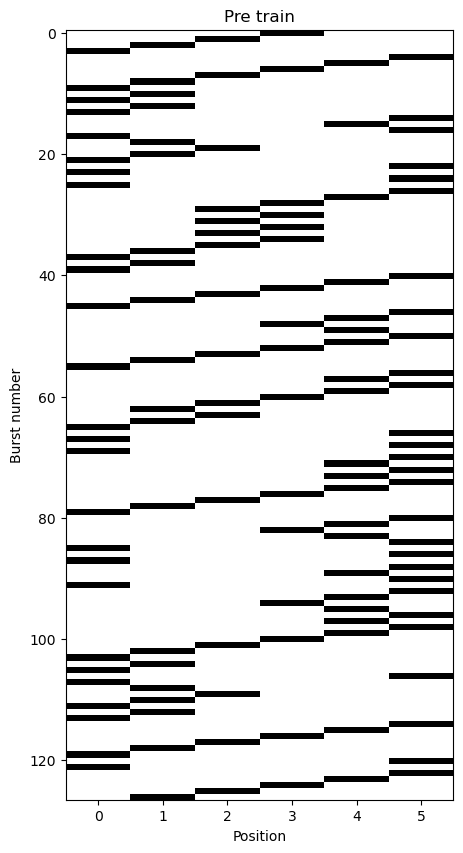

In [39]:
xtplot = np.zeros((len(pre_train_movement_df), 1 + max(pre_train_movement_df["position"])))
for i in pre_train_movement_df.index:
    xtplot[i, pre_train_movement_df.loc[i, "position"]] = 1

plt.figure(figsize = (5, 10))
plt.imshow(xtplot, aspect = "auto", interpolation = "none", cmap = "Greys")
plt.title("No stim")
plt.ylabel("Burst number")
plt.xlabel("Position")

Text(0.5, 0, 'Position')

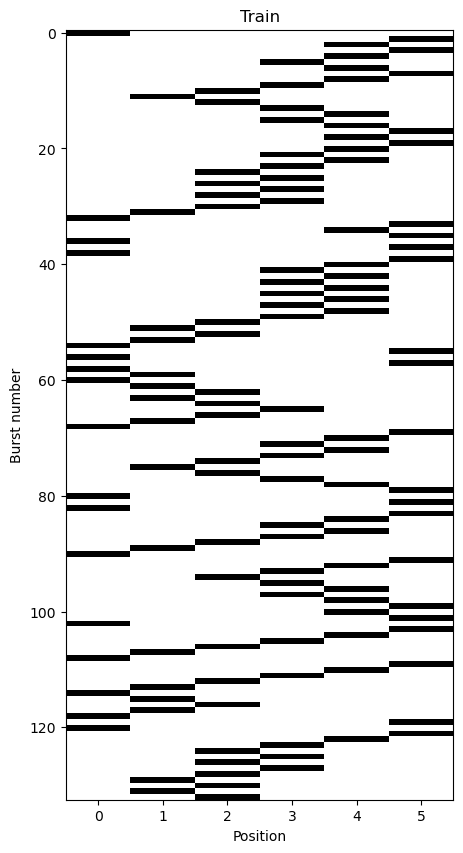

In [41]:
xtplot = np.zeros((len(train_movement_df), 1 + max(train_movement_df["position"])))
for i in train_movement_df.index:
    xtplot[i, train_movement_df.loc[i, "position"]] = 1

plt.figure(figsize = (5, 10))
plt.imshow(xtplot, aspect = "auto", interpolation = "none", cmap = "Greys")
plt.title("Stim")
plt.ylabel("Burst number")
plt.xlabel("Position")

In [7]:

midway = (min(train_movement_df["frameno"]) + max(train_movement_df["frameno"]))/2

first_half_train_movement_df = train_movement_df.loc[train_movement_df["frameno"] < midway, :].reset_index()
second_half_train_movement_df = train_movement_df.loc[train_movement_df["frameno"] > midway, :].reset_index()

midway = (min(pre_train_movement_df["frameno"]) + max(pre_train_movement_df["frameno"]))/2

first_half_pre_train_movement_df = pre_train_movement_df.loc[pre_train_movement_df["frameno"] < midway, :].reset_index()
second_half_pre_train_movement_df = pre_train_movement_df.loc[pre_train_movement_df["frameno"] > midway, :].reset_index()

In [8]:
train_transition_df = m1da.build_trainsition_df(train_movement_df, world)
pre_train_transition_df = m1da.build_trainsition_df(pre_train_movement_df, world)
first_half_train_transition_df = m1da.build_trainsition_df(first_half_train_movement_df, world)
second_half_train_transition_df = m1da.build_trainsition_df(second_half_train_movement_df, world)

first_half_pre_train_transition_df = m1da.build_trainsition_df(first_half_pre_train_movement_df, world)
second_half_pre_train_transition_df = m1da.build_trainsition_df(second_half_pre_train_movement_df, world)

train_transition_df

,leftward,rightward,total,proportion left,object
0,14.0,3.0,17.0,0.823529,1
1,8.0,8.0,16.0,0.500000,0
2,13.0,9.0,22.0,0.590909,0
3,15.0,13.0,28.0,0.535714,0
4,19.0,8.0,27.0,0.703704,1
5,14.0,8.0,22.0,0.636364,0


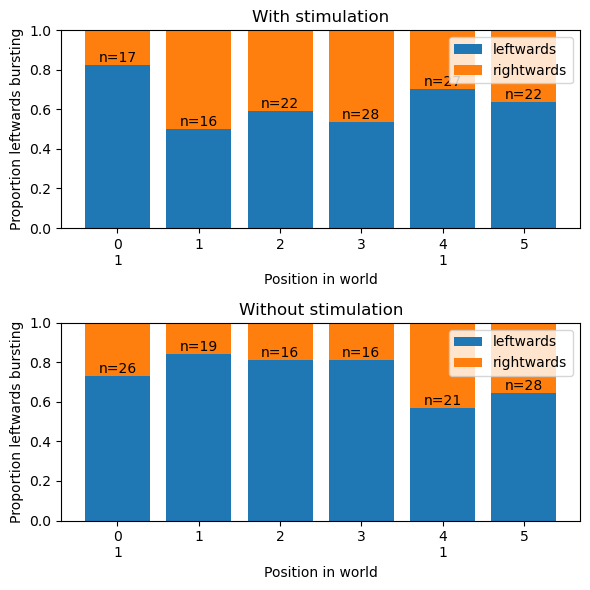

In [9]:
plt.figure(figsize = (6, 6))
ax = plt.subplot(211)
plt.title("With stimulation")
m1da.make_probability_bars(train_transition_df, world)

ax = plt.subplot(212)
plt.title("Without stimulation")
m1da.make_probability_bars(pre_train_transition_df, world)

plt.tight_layout()

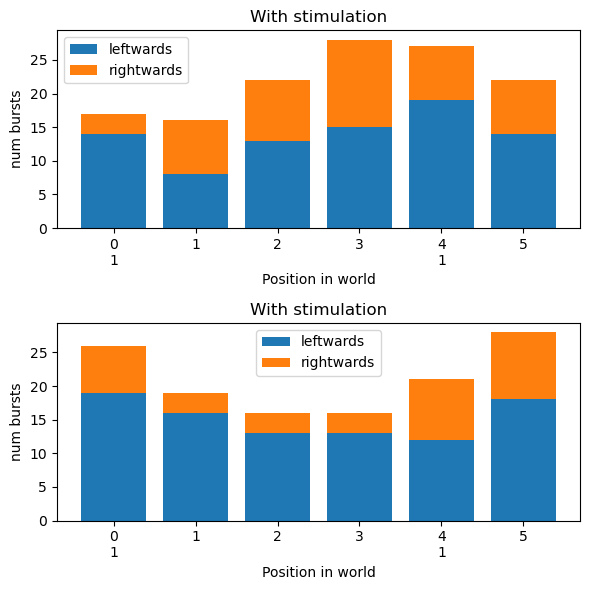

In [10]:
plt.figure(figsize = (6, 6))
ax = plt.subplot(211)
plt.title("With stimulation")
m1da.make_count_bars(train_transition_df, world)

ax = plt.subplot(212)
plt.title("Without stimulation")
m1da.make_count_bars(pre_train_transition_df, world)

plt.tight_layout()

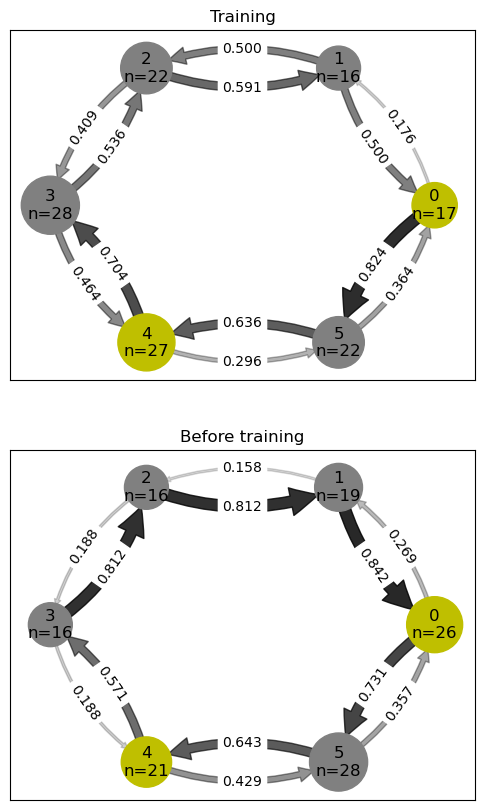

In [11]:
plt.figure(figsize = (6, 10))
plt.subplot(211)
plt.title("Training")
m1da.make_network_graph(train_transition_df, world)
plt.subplot(212)
plt.title("Before training")
m1da.make_network_graph(pre_train_transition_df, world)

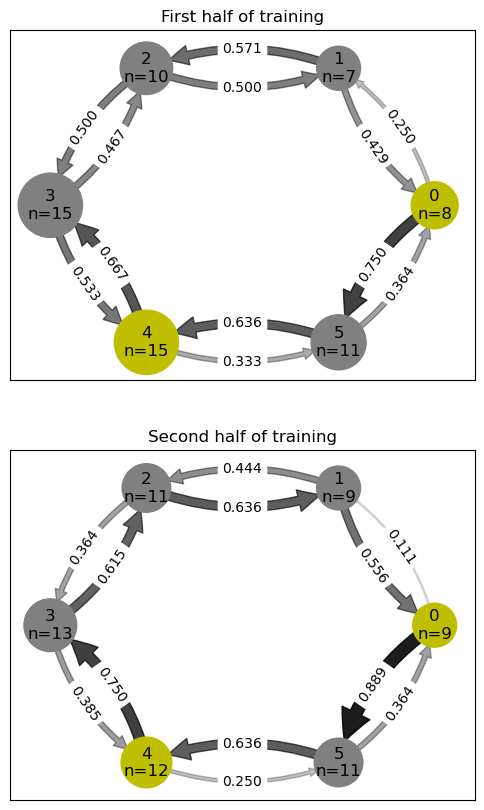

In [12]:
plt.figure(figsize = (6, 10))
plt.subplot(211)
plt.title("First half of training")
m1da.make_network_graph(first_half_train_transition_df, world)
plt.subplot(212)
plt.title("Second half of training")
m1da.make_network_graph(second_half_train_transition_df, world)

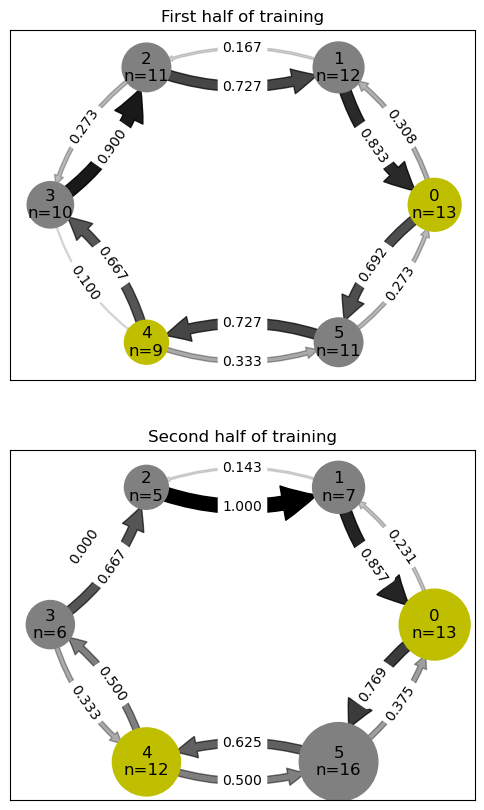

In [13]:
plt.figure(figsize = (6, 10))
plt.subplot(211)
plt.title("First half of training")
m1da.make_network_graph(first_half_pre_train_transition_df, world)
plt.subplot(212)
plt.title("Second half of training")
m1da.make_network_graph(second_half_pre_train_transition_df, world)